In [ ]:
import cv2
import math
import time
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("coins.jpg")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.5)
edges = cv2.Canny(blur, 100, 200)

def hough_circles_manual(edges, min_radius=20, max_radius=80, dp=1.0, threshold=30, min_dist=40):
    """Manual implementation of Hough Circle Transform"""
    h, w = edges.shape
    
    # Scale down accumulator for speed (based on dp)
    acc_h, acc_w = int(h / dp), int(w / dp)
    
    # Create 3D accumulator array (cx, cy, r)
    num_radii = max_radius - min_radius + 1
    accumulator = np.zeros((acc_h, acc_w, num_radii), dtype=np.uint32)
    
    # Get edge points
    edge_points = np.column_stack(np.where(edges > 0))
    
    print(f"Processing {len(edge_points)} edge points...")
    
    # For each edge point
    for y, x in edge_points[:5000]:  # Limit points for speed
        # For each possible radius
        for r_idx, r in enumerate(range(min_radius, max_radius + 1)):
            # Sample angles (not all 360 for speed)
            for theta in np.linspace(0, 2 * np.pi, 72):  # 5 degree steps
                # Calculate possible center
                cx = int((x + r * math.cos(theta)) / dp)
                cy = int((y + r * math.sin(theta)) / dp)
                
                # Check bounds
                if 0 <= cx < acc_w and 0 <= cy < acc_h:
                    accumulator[cy, cx, r_idx] += 1
    
    # Find circles from accumulator peaks
    circles = []
    
    # Threshold accumulator
    acc_threshold = threshold
    peaks = np.argwhere(accumulator > acc_threshold)
    
    # Sort by vote count
    if len(peaks) > 0:
        peak_values = accumulator[peaks[:, 0], peaks[:, 1], peaks[:, 2]]
        sorted_indices = np.argsort(-peak_values)  # Descending
        
        for idx in sorted_indices:
            cy_bin, cx_bin, r_idx = peaks[idx]
            votes = accumulator[cy_bin, cx_bin, r_idx]
            
            if votes < acc_threshold:
                continue
            
            # Convert back to image coordinates
            cx = int(cx_bin * dp)
            cy = int(cy_bin * dp)
            r = r_idx + min_radius
            
            # Check if too close to existing circles
            too_close = False
            for existing_cx, existing_cy, existing_r in circles:
                dist = math.sqrt((cx - existing_cx)**2 + (cy - existing_cy)**2)
                if dist < min_dist:
                    too_close = True
                    break
            
            if not too_close:
                circles.append((cx, cy, r))
                
                # Suppress nearby peaks in accumulator
                y_min = max(0, cy_bin - int(min_dist/dp))
                y_max = min(acc_h, cy_bin + int(min_dist/dp))
                x_min = max(0, cx_bin - int(min_dist/dp))
                x_max = min(acc_w, cx_bin + int(min_dist/dp))
                
                accumulator[y_min:y_max, x_min:x_max, :] = 0
    
    return circles

# Run manual Hough
print("Running Manual Hough Transform...")
start_hough = time.time()
hough_circles = hough_circles_manual(
    edges, 
    min_radius=20,
    max_radius=80,
    dp=1.2, 
    threshold=30,
    min_dist=30
)
end_hough = time.time()

# RANSAC CIRCLES
# Get edge points (y, x format)
edge_points = np.column_stack(np.where(edges > 0))

def circle_from_3pts(p1, p2, p3):
    """Calculate circle from 3 points. p1, p2, p3 are in (y, x) format."""
    # Convert from (y, x) to (x, y) for the circle math
    x1, y1 = p1[1], p1[0]
    x2, y2 = p2[1], p2[0]
    x3, y3 = p3[1], p3[0]
    
    temp = x2**2 + y2**2
    bc = (x1**2 + y1**2 - temp) / 2
    cd = (temp - x3**2 - y3**2) / 2
    det = (x1 - x2)*(y2 - y3) - (x2 - x3)*(y1 - y2)
    
    if abs(det) < 1e-6:
        return None
    
    cx = (bc*(y2 - y3) - cd*(y1 - y2)) / det
    cy = ((x1 - x2)*cd - (x2 - x3)*bc) / det
    r = math.sqrt((cx - x1)**2 + (cy - y1)**2)
    
    # Filter unrealistic circles
    if r < 20 or r > 80:
        return None
        
    return int(cx), int(cy), int(r)

def ransac_circle_detection(points, iterations=2000, threshold=3, min_inliers=30):
    """RANSAC algorithm for circle detection."""
    points_array = points.copy()
    detected_circles = []
    
    while len(points_array) > 200:  # Stop when too few points remain
        best_circle = None
        best_inliers = []
        best_score = 0
        
        for _ in range(iterations):
            # Randomly sample 3 points
            indices = np.random.choice(len(points_array), 3, replace=False)
            p1, p2, p3 = points_array[indices]
            
            # Get circle from points
            circle = circle_from_3pts(p1, p2, p3)
            if circle is None:
                continue
                
            cx, cy, r = circle
            
            # Find inliers using vectorized calculation
            y_coords = points_array[:, 0]
            x_coords = points_array[:, 1]
            distances = np.sqrt((x_coords - cx)**2 + (y_coords - cy)**2)
            inlier_mask = np.abs(distances - r) < threshold
            
            inlier_count = np.sum(inlier_mask)
            
            # Update best circle
            if inlier_count > best_score:
                best_score = inlier_count
                best_circle = circle
                best_inliers = inlier_mask
        
        # Check if we found a good circle
        if best_circle is not None and best_score >= min_inliers:
            detected_circles.append(best_circle)
            
            # Remove inliers for next iteration
            points_array = points_array[~best_inliers]
        else:
            break  # No more circles to find
    
    return detected_circles

# Run RANSAC
print("\nRunning RANSAC...")
start_ransac = time.time()
ransac_circles = ransac_circle_detection(
    edge_points,
    iterations=50000,
    threshold=1, 
    min_inliers=40
)
end_ransac = time.time()

output = img.copy()

Running Manual Hough Transform...
Processing 2990 edge points...

Running RANSAC...



PERFORMANCE SUMMARY:
Hough detected 24 circles
Hough Time: 41.07s

RANSAC detected 24 circles
RANSAC Time: 64.49s
Edge points: 2990

ASSIGNMENT REQUIRED OUTPUT FORMAT:

Hough Method Result:
Circle 1: Center: (63, 37), Radius: 24
Circle 2: Center: (204, 154), Radius: 24
Circle 3: Center: (175, 84), Radius: 24
Circle 4: Center: (134, 52), Radius: 24
Circle 5: Center: (46, 97), Radius: 24
Circle 6: Center: (46, 276), Radius: 24
Circle 7: Center: (216, 105), Radius: 24
Circle 8: Center: (196, 201), Radius: 24
Circle 9: Center: (130, 286), Radius: 24
Circle 10: Center: (26, 192), Radius: 24
Circle 11: Center: (21, 136), Radius: 24
Circle 12: Center: (63, 163), Radius: 24
Circle 13: Center: (177, 289), Radius: 24
Circle 14: Center: (150, 189), Radius: 24
Circle 15: Center: (160, 136), Radius: 24
Circle 16: Center: (57, 228), Radius: 24
Circle 17: Center: (91, 260), Radius: 24
Circle 18: Center: (93, 199), Radius: 24
Circle 19: Center: (174, 242), Radius: 24
Circle 20: Center: (87, 121), Rad

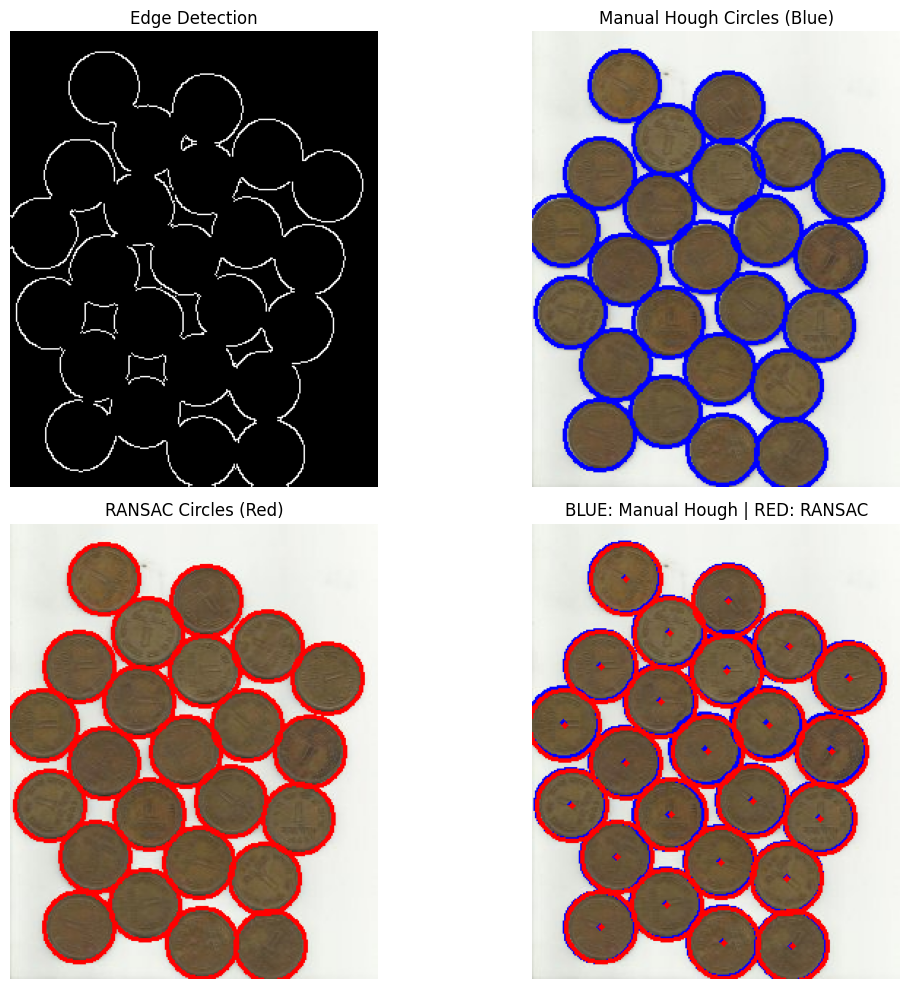

In [5]:
# Draw Hough circles (BLUE)
for cx, cy, r in hough_circles:
    cv2.circle(output, (cx, cy), r, (255, 0, 0), 2)
    cv2.circle(output, (cx, cy), 2, (255, 0, 0), -1)  # Center point

# Draw RANSAC circles (RED)
for cx, cy, r in ransac_circles:
    cv2.circle(output, (cx, cy), r, (0, 0, 255), 2)
    cv2.circle(output, (cx, cy), 2, (0, 0, 255), -1)  # Center point

print("\n" + "="*50)
print("PERFORMANCE SUMMARY:")
print("="*50)
print(f"Hough detected {len(hough_circles)} circles")
print(f"Hough Time: {end_hough - start_hough:.2f}s")
print(f"\nRANSAC detected {len(ransac_circles)} circles")
print(f"RANSAC Time: {end_ransac - start_ransac:.2f}s")
print(f"Edge points: {len(edge_points)}")

print("\n" + "="*50)
print("ASSIGNMENT REQUIRED OUTPUT FORMAT:")
print("="*50)

print("\nHough Method Result:")
for i, (cx, cy, r) in enumerate(hough_circles, 1):
    print(f"Circle {i}: Center: ({cx}, {cy}), Radius: {r}")

print("\nRANSAC Method Result:")
for i, (cx, cy, r) in enumerate(ransac_circles, 1):
    print(f"Circle {i}: Center: ({cx}, {cy}), Radius: {r}")

plt.figure(figsize=(12, 10))

# Original edges
plt.subplot(2, 2, 1)
plt.imshow(edges, cmap='gray')
plt.title("Edge Detection")
plt.axis('off')

# Hough circles only
hough_only = img.copy()
for cx, cy, r in hough_circles:
    cv2.circle(hough_only, (cx, cy), r, (255, 0, 0), 2)
plt.subplot(2, 2, 2)
plt.imshow(cv2.cvtColor(hough_only, cv2.COLOR_BGR2RGB))
plt.title("Manual Hough Circles (Blue)")
plt.axis('off')

# RANSAC circles only
ransac_only = img.copy()
for cx, cy, r in ransac_circles:
    cv2.circle(ransac_only, (cx, cy), r, (0, 0, 255), 2)
plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(ransac_only, cv2.COLOR_BGR2RGB))
plt.title("RANSAC Circles (Red)")
plt.axis('off')

# Combined result
plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("BLUE: Manual Hough | RED: RANSAC")
plt.axis('off')

plt.tight_layout()
plt.show()